In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline



In [2]:
words = open("names.txt", "r").read().splitlines()

In [3]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [83]:
block_size = 3
X, Y = [], []

for w in words:

    context = [0] * block_size

    for ch in w + ".":
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)

In [84]:
C = torch.randn((27, 2))
w1 = torch.randn((6, 100))
b1 = torch.randn(100)
w2 = torch.randn((100,27))
b2 = torch.randn(27)
parameters = [C, w1, b1, w2, b2]

for p in parameters:
    p.requires_grad = True

In [85]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10 ** lre

In [86]:
lossi = []
lri = []

for i in range (1000):

    # Minibatch Construct:
    ix = torch.randint(0, X.shape[0], (32, )) #type:ignore

    # Forward:
    emb = C[X[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 2*block_size) @ w1 + b1) # (32, 100)
    logits = h @ w2 + b2 # (32, 27)

    # ==========
    #counts = logits.exp()
    #prob = counts / counts.sum(1, keepdim=True)
    #loss = -prob[torch.arange(32), Y].log().mean()

    # All the above steps are less efficient yet equal to:
    loss = F.cross_entropy(logits, Y[ix]) #type:ignore
    # Backward:
    for p in parameters:
        p.grad = None
    loss.backward()

    # Update
    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad #type: Ignore

    # Track
    lri.append(lr)
    lossi.append(loss.item())

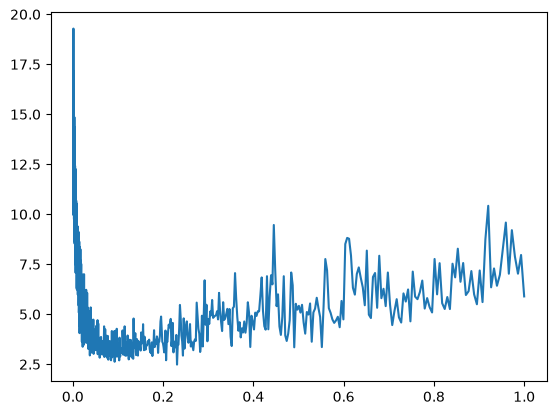

In [87]:
plt.plot(lri, lossi)